# 01 – Explorative Datenanalyse: Casting-Datensatz

Gussteile (Pumpenlaufräder), zwei Klassen: `def_front` (defekt) und `ok_front` (in Ordnung).

In [1]:
import sys, collections
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))
import numpy as np, matplotlib.pyplot as plt
from PIL import Image
from common import OFFICIAL_DIR, ORIGINAL_DIR, get_split

## Klassenverteilung

In [2]:
rows = {}
for name, folder in [('official/train', OFFICIAL_DIR/'train'), ('official/test', OFFICIAL_DIR/'test'), ('512 originals', ORIGINAL_DIR)]:
    rows[name] = {c: len(list((folder/c).glob('*.jpeg'))) for c in ['def_front', 'ok_front']}
rows

{'official/train': {'def_front': 3758, 'ok_front': 2875},
 'official/test': {'def_front': 453, 'ok_front': 262},
 '512 originals': {'def_front': 781, 'ok_front': 519}}

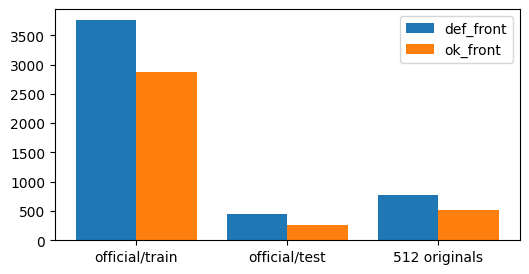

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
names = list(rows)
ax.bar(np.arange(3) - 0.2, [rows[n]['def_front'] for n in names], 0.4, label='def_front')
ax.bar(np.arange(3) + 0.2, [rows[n]['ok_front'] for n in names], 0.4, label='ok_front')
ax.set_xticks(range(3)); ax.set_xticklabels(names); ax.legend(); plt.show()

## Beispielbilder

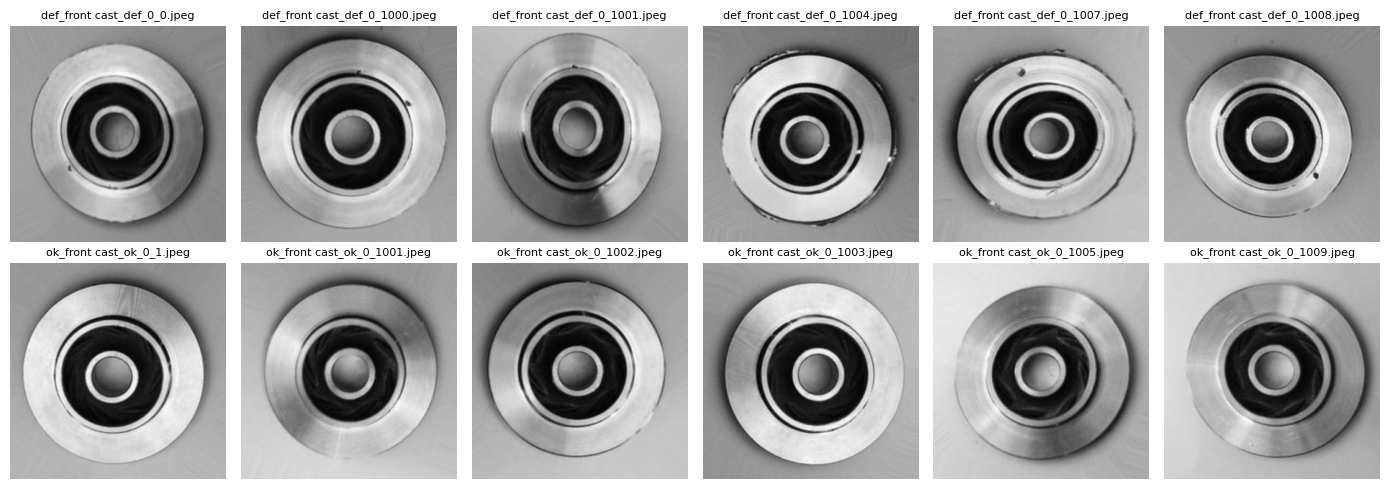

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for r, c in enumerate(['def_front', 'ok_front']):
    files = sorted((OFFICIAL_DIR/'train'/c).glob('*.jpeg'))[:6]
    for a, f in zip(axes[r], files):
        a.imshow(Image.open(f).convert('L'), cmap='gray'); a.set_title(f'{c} {f.name}', fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

## Helligkeit pro Klasse
Wenn sich die Klassen schon in der mittleren Helligkeit unterscheiden, kann ein Modell abkürzen, statt auf Defekte zu schauen.

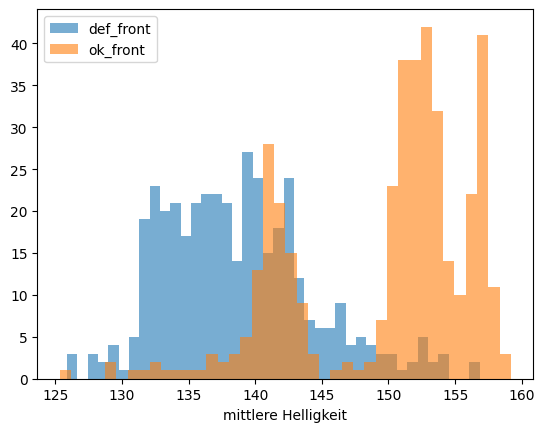

In [5]:
for c in ['def_front', 'ok_front']:
    files = sorted((OFFICIAL_DIR/'train'/c).glob('*.jpeg'))[:400]
    m = [np.asarray(Image.open(f).convert('L')).mean() for f in files]
    plt.hist(m, bins=40, alpha=0.6, label=c)
plt.xlabel('mittlere Helligkeit'); plt.legend(); plt.show()

## Leakage-Hinweis
Der 300×300-Satz ist aus den 1300 Originalbildern (512×512) augmentiert. Varianten desselben Teils können daher in Train **und** Test des offiziellen Splits stehen. Deshalb gibt es zusätzlich den `clean`-Split nur auf den Originalen (70/15/15, stratifiziert).

In [6]:
for s in ['official', 'clean']:
    parts = get_split(s)
    print(s, {k: (len(v), sum(y for _, y in v)) for k, v in parts.items()}, '(n, davon defekt)')

official {'train': (5638, 3194), 'val': (995, 564), 'test': (715, 453)} (n, davon defekt)
clean {'train': (910, 547), 'val': (195, 117), 'test': (195, 117)} (n, davon defekt)
